In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [5]:
path = 'data/Austin_Animal_Center_Outcomes.csv'
animalcenter_df = pd.read_csv(path)

In [6]:
display(animalcenter_df)

,ID,Outcome Date,Animal ID,Name,Outcome Status,Euthanasia Reason,Type,Sex,Spayed/Neutered,Primary Breed,Primary Color,Secondary Color,Date of Birth,Intake Date,Days in Shelter,Timestamp
0,103401,2026 Oct 21 01:56:00 PM,35559,Cameron,Return to Habitat,NaN,Cat,Male,Yes,Domestic Shorthair,Blue,White,2026 May 10 12:00:00 AM,2026 Oct 08 01:50:00 PM,13,2026 Oct 21 02:00:13 PM
1,103382,2026 Oct 21 01:17:34 PM,31010,Odie,Adopted,NaN,Dog,Male,Yes,Australian Cattle Dog,White,Brown,2026 May 13 12:00:00 AM,2026 Oct 12 05:03:00 PM,9,2026 Oct 21 02:00:13 PM
2,103366,2026 Oct 21 12:33:00 PM,36844,Owen,Reclaimed,NaN,Dog,Male,Yes,American Pit Bull Terrier,Blue,White,2024 Oct 20 12:00:00 AM,2026 Oct 20 11:51:00 AM,1,2026 Oct 21 01:00:13 PM
3,103364,2026 Oct 21 12:24:43 PM,36787,Baloo,Adopted,NaN,Puppy,Male,Yes,Chihuahua - Long-hair,Cream,NaN,2026 Aug 06 12:00:00 AM,2026 Oct 19 12:07:00 PM,2,2026 Oct 21 01:00:13 PM
4,103363,2026 Oct 21 12:24:00 PM,36502,NaN,Transfer Out,NaN,Dog,Male,Yes,English Bulldog,Fawn,Merle,2024 Oct 20 12:00:00 AM,2026 Oct 16 07:05:00 PM,5,2026 Oct 21 01:00:13 PM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18990,13159,2025 May 06 11:19:00 AM,6338,SUZY,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Brown Tabby,NaN,2019 Mar 17 12:00:00 AM,2025 Mar 17 12:00:00 AM,50,2026 Oct 21 12:17:28 AM
18991,13052,2025 May 05 06:53:00 PM,5970,OLLI,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Orange Tabby,NaN,2014 Apr 20 12:00:00 AM,2025 May 02 12:00:00 AM,3,2026 Oct 21 12:17:28 AM
18992,13060,2025 May 05 05:15:00 PM,6885,NaN,Transfer Out,NaN,Dog,Female,No,German Shepherd,Buff,Cream,2025 Jan 05 12:00:00 AM,2025 May 05 10:40:00 AM,0,2026 Oct 21 12:17:28 AM
18993,12912,2025 May 05 11:22:00 AM,5994,NaN,Unresolved File,NaN,Cat,Male,No,Domestic Shorthair,Black,NaN,2023 Apr 20 12:00:00 AM,2023 May 03 12:00:00 AM,733,2026 Oct 21 12:17:28 AM


In [13]:
# I wanted to analyse the types of animals in this dataset first, so I got the total number of all the type of animals in this dataset.
# It's interesting that the dataset separates puppy/kitten from dog/cat, but I could not find what the cutoff age is.
# There's also a category for 'Mammal' that I might need to dive into later.
# This dataset shows that highest type of animals in the Austin Animal Center is cats then dogs.
animalcenter_df.Type.value_counts()

Type
Cat                   9219
Dog                   6734
Kitten                1553
Mammal                 877
Puppy                  308
Rabbit                  75
Guinea Pig              51
Reptile                 32
Bird (wildlife)         30
Bird                    29
Fowl                    24
Rodent                  22
Marsupial               15
Reptile (Wildlife)      11
Ferret                   4
Crab/fish                4
Sheep                    2
Goat                     2
Insect / Arachnid        1
Zoo                      1
Pig                      1
Name: count, dtype: int64

In [11]:
# I want to start analysing some data with all the cats, but I had to combine the kittens with the cats first.
cats_df = animalcenter_df[animalcenter_df.Type.isin(['Cat', 'Kitten'])]
cats_df

,ID,Outcome Date,Animal ID,Name,Outcome Status,Euthanasia Reason,Type,Sex,Spayed/Neutered,Primary Breed,Primary Color,Secondary Color,Date of Birth,Intake Date,Days in Shelter,Timestamp
0,103401,2026 Oct 21 01:56:00 PM,35559,Cameron,Return to Habitat,NaN,Cat,Male,Yes,Domestic Shorthair,Blue,White,2026 May 10 12:00:00 AM,2026 Oct 08 01:50:00 PM,13,2026 Oct 21 02:00:13 PM
5,103362,2026 Oct 21 12:23:00 PM,31961,Stanley,Adopted,NaN,Cat,Male,Yes,Domestic Shorthair,Brown Tabby,NaN,2024 Aug 23 12:00:00 AM,2026 Aug 23 09:18:00 AM,59,2026 Oct 21 01:00:13 PM
8,103330,2026 Oct 21 11:12:00 AM,36030,Kai,Transfer Out,NaN,Cat,Unknown,Unknown,Domestic Shorthair,Black,NaN,2021 Oct 15 12:00:00 AM,2026 Oct 15 11:10:00 AM,6,2026 Oct 21 12:00:10 PM
9,103300,2026 Oct 20 06:35:47 PM,35838,Madeleine,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Seal Point,NaN,2025 Apr 13 12:00:00 AM,2026 Oct 12 04:11:00 PM,8,2026 Oct 21 12:15:10 AM
10,103281,2026 Oct 20 06:04:39 PM,35870,Molly,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Blue Cream Tortoiseshell,NaN,2020 Oct 13 12:00:00 AM,2026 Oct 13 12:09:00 PM,7,2026 Oct 21 12:15:10 AM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18989,13192,2025 May 06 11:57:00 AM,6807,Flint,Adopted,NaN,Cat,Male,Yes,RUSSIAN BLUE,Grey,NaN,2021 May 02 12:00:00 AM,2025 May 02 12:00:00 AM,4,2026 Oct 21 12:17:28 AM
18990,13159,2025 May 06 11:19:00 AM,6338,SUZY,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Brown Tabby,NaN,2019 Mar 17 12:00:00 AM,2025 Mar 17 12:00:00 AM,50,2026 Oct 21 12:17:28 AM
18991,13052,2025 May 05 06:53:00 PM,5970,OLLI,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Orange Tabby,NaN,2014 Apr 20 12:00:00 AM,2025 May 02 12:00:00 AM,3,2026 Oct 21 12:17:28 AM
18993,12912,2025 May 05 11:22:00 AM,5994,NaN,Unresolved File,NaN,Cat,Male,No,Domestic Shorthair,Black,NaN,2023 Apr 20 12:00:00 AM,2023 May 03 12:00:00 AM,733,2026 Oct 21 12:17:28 AM


In [14]:
# Next I tried to see all of the different breeds and counts of the cats.
# Domestic Shorthair outbeats all other breeds by a large amount.
cats_df['Primary Breed'].value_counts()

Primary Breed
Domestic Shorthair      9634
Domestic Medium Hair     682
Domestic Long Hair       218
Siamese                  141
Russian                   26
American Shorthair        13
Persian                   11
Maine Coon                 8
Snowshoe                   7
Scottish Fold              7
Sphynx                     7
RUSSIAN BLUE               5
Bengal                     3
British Shorthair          2
American Bobtail           2
Burmese                    1
Colorpoint Shorthair       1
Tonkinese                  1
BRITISH SH                 1
Ragdoll                    1
Himalayan                  1
Name: count, dtype: int64

In [48]:
# I tried to get some statistics on how long these cats usually stayed in the Austin Animal Center.
# There is probably an error in this dataset as the min number is -4 days which did not make sense.
# Max is 733 days, mean is 21 days.

# Remove missing values
cats_df['Days in Shelter'] = pd.to_numeric(cats_df['Days in Shelter'])
cats_df['Days in Shelter'].describe()

count    10772.000000
mean        21.169421
std         34.586733
min         -4.000000
25%          4.000000
50%          8.000000
75%         28.000000
max        733.000000
Name: Days in Shelter, dtype: float64

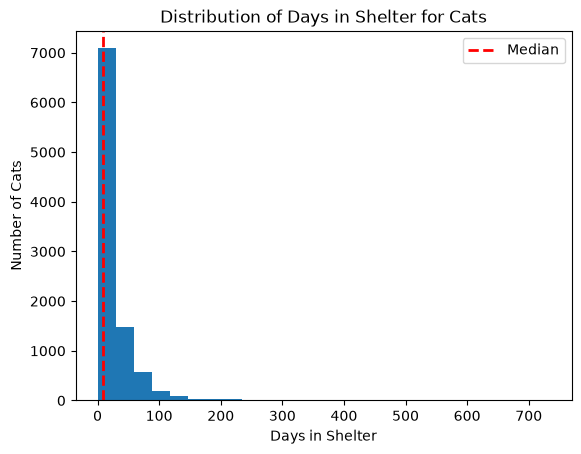

In [49]:
# I wanted to plot this on a graph to see the distribution of days in shelter for cats.
# The dataset has a lot of animals being transfered out on their 0 day in the center, so I only wanted to see the cats that stayed more than 0 days.
# Most cats stay less than 100 days.
cat_days_filtered = cats_df['Days in Shelter'][cats_df['Days in Shelter'] > 0]

plt.hist(cat_days_filtered, bins=25)
plt.title('Distribution of Days in Shelter for Cats')
plt.xlabel('Days in Shelter')
plt.ylabel('Number of Cats')
plt.axvline(cat_days_filtered.median(), linestyle='dashed', color='red', linewidth=2, label='Median')
plt.legend()
plt.show()

In [51]:
# I want to see the 10 cats that stayed in the animal center for the longest.
# 7 out of 10 cat did get adopted, 1 transfered out, 1 euthanized and one unresolved file???

top_10_cats = cats_df.sort_values(by='Days in Shelter', ascending=False).head(10)
top_10_cats

,ID,Outcome Date,Animal ID,Name,Outcome Status,Euthanasia Reason,Type,Sex,Spayed/Neutered,Primary Breed,Primary Color,Secondary Color,Date of Birth,Intake Date,Days in Shelter,Timestamp
18993,12912,2025 May 05 11:22:00 AM,5994,NaN,Unresolved File,NaN,Cat,Male,No,Domestic Shorthair,Black,NaN,2023 Apr 20 12:00:00 AM,2023 May 03 12:00:00 AM,733,2026 Oct 21 12:17:28 AM
14674,34932,2025 Aug 23 09:52:00 AM,6012,Venus,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Torbie,White,2022 Dec 21 12:00:00 AM,2023 Dec 27 12:00:00 AM,605,2026 Oct 21 12:16:45 AM
12495,45729,2025 Oct 29 01:00:51 PM,6033,Simone,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Brown Tabby,White,2017 Sep 04 12:00:00 AM,2024 May 10 12:00:00 AM,537,2026 Oct 21 12:16:28 AM
7929,66806,2026 Apr 09 06:27:48 PM,6135,Becky,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Black,White,2012 Nov 27 12:00:00 AM,2024 Nov 27 12:00:00 AM,498,2026 Oct 21 12:15:59 AM
10717,53493,2025 Dec 26 05:38:00 PM,6076,Jean-Ralphio,Adopted,NaN,Cat,Male,Yes,Domestic Medium Hair,Cream Ginger Tabby,White,2022 Aug 25 12:00:00 AM,2024 Aug 25 12:00:00 AM,488,2026 Oct 21 12:16:16 AM
6554,72463,2026 May 12 12:01:00 PM,6237,Lola,Adopted,NaN,Cat,Female,Yes,Domestic Shorthair,Brown Tabby,NaN,2024 Feb 18 12:00:00 AM,2025 Feb 18 12:00:00 AM,448,2026 Oct 21 12:15:50 AM
5228,78932,2026 Jun 14 10:52:00 AM,6789,Merida,Euthanized,Trauma,Cat,Male,Yes,Domestic Shorthair,Brown Tabby,NaN,2025 Mar 17 12:00:00 AM,2025 May 01 12:00:00 AM,409,2026 Oct 21 12:15:40 AM
16258,27797,2025 Jul 16 10:14:00 AM,6048,Vincent,Adopted,NaN,Cat,Male,Yes,Domestic Long Hair,Blue,NaN,2014 Sep 21 12:00:00 AM,2024 Jun 15 12:00:00 AM,396,2026 Oct 21 12:16:58 AM
18501,13008,2025 May 20 01:46:00 PM,6035,NaN,Transfer Out,NaN,Cat,Male,No,Domestic Shorthair,Blue,NaN,2024 May 04 12:00:00 AM,2024 May 13 12:00:00 AM,372,2026 Oct 21 12:17:20 AM
16375,27153,2025 Jul 12 04:28:48 PM,6053,Fritz,Adopted,NaN,Cat,Male,Yes,Domestic Shorthair,Brown Tabby,NaN,2019 Jul 08 12:00:00 AM,2024 Jul 08 12:00:00 AM,369,2026 Oct 21 12:17:00 AM


In [59]:
# I want to see all the Outcome Status of the cats.
# There are multiple status for adopted including Adopted Altered, Adopted Offset, so I combined all of the status that contains the word 'Adopted'
# It was good to see that most cats do get adopted, but 483 still got euthanized and 141 DOA(Dead on Arrival) ;(

cats_df['Outcome Status'].replace(
    cats_df['Outcome Status'][cats_df['Outcome Status'].str.contains('Adopted')].unique(),'Adopted'
).value_counts()

Outcome Status
Adopted                          5687
Transfer Out                     3660
Euthanized                        483
Return to Habitat                 297
Reclaimed                         288
DOA                               141
Unassisted Death                  126
Unassisted Death - In Foster       36
Redemption (Offsite)               11
Unassisted Death - In Transit      10
DOA - Final Disposition             7
Unresolved File                     6
Interred                            5
DOA - Released to Owner             4
Cremated                            3
Lost                                3
Escaped                             2
Euthanasia - RTO                    2
Bite Quarantine (Home)              1
Name: count, dtype: int64

In [65]:
# I want to look into all the reasons why the cats where being euthanized, so I filtered out all of them.
cats_df[cats_df['Outcome Status'] == 'Euthanized']['Euthanasia Reason'].value_counts()

Euthanasia Reason
Suffering       312
Injured          69
Agonal           35
Trauma           15
Neurological     13
Congenital       12
Rabies Risk       9
Cardiac           8
Toxicity          5
Aggression        1
Name: count, dtype: int64

In [66]:
# Then tried to take a look at all the primary colors of the cat
cats_df['Primary Color'].value_counts()

Primary Color
Brown Tabby                    2745
Black                          2285
Orange Tabby                   1297
White                           690
Blue                            676
                               ... 
Silver Tortoiseshell Calico       1
Shaded                            1
Ticked                            1
Silver Patch Tabby                1
Patch Tabby                       1
Name: count, Length: 65, dtype: int64

In [63]:
# Also wanted to see if the colors of the adopted cats are the same and it looks fairly the same
cats_df[cats_df['Outcome Status'] == 'Adopted']['Primary Color'].value_counts()

Primary Color
Brown Tabby                 1309
Black                       1030
Orange Tabby                 618
Blue                         354
White                        345
Grey Tabby                   242
Calico                       216
Torbie                       211
Tortoiseshell                166
Cream Ginger Tabby           100
Grey                          74
Seal Point                    62
BLUE TABBY                    60
Flame Point                   38
Cream                         35
Tabby                         31
Orange                        24
Lilac Point                   24
Muted Tortoiseshell           24
Muted Calico                  20
Blue Ticked                   20
Silver Tabby                  19
LYNX PT                       19
Blue Cream Tortoiseshell      13
Brown                         10
Tabby Point                    9
Smoke                          9
Blue Cream Calico              8
Torti Point                    8
Buff Tiger                   

In [73]:
# I want to compare the days in shelter between the cats and dogs
# The numbers larger than 1000 has a "," after the 3 digits so I had to change then to all just be integers only
dogs_df = animalcenter_df[animalcenter_df.Type.isin(['Dog', 'Puppy'])]
dogs_df['Days in Shelter'] = pd.to_numeric(
    dogs_df['Days in Shelter'].astype(str).str.replace(',', '')
)
dog_days_filtered = dogs_df['Days in Shelter'][dogs_df['Days in Shelter'] > 0]

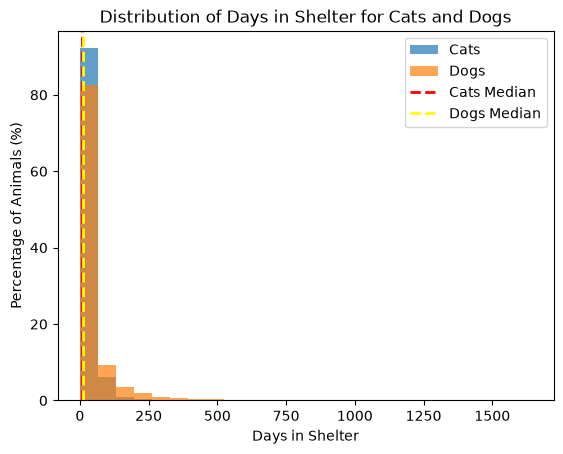

In [83]:
# Instead of directly comparing the total number of cats vs dogs and their days in shelter, I wanted to see the graph in percentage in their own type.
# The median of days in shelter for cats and dogs are about the same with dogs slightly longer.
# Graph shows that dogs typically stay in shelter for longer.

# Unified bins for both graphs
import numpy as np
bin = np.linspace(
    min(cat_days_filtered.min(), dog_days_filtered.min()),
    max(cat_days_filtered.max(), dog_days_filtered.max()),
    26
)

plt.hist(cat_days_filtered, bins=bin, label='Cats', alpha=0.7, weights=[100 / len(cat_days_filtered)] * len(cat_days_filtered))
plt.hist(dog_days_filtered, bins=bin, label='Dogs', alpha=0.7, weights=[100 / len(dog_days_filtered)] * len(dog_days_filtered))
plt.title('Distribution of Days in Shelter for Cats and Dogs')
plt.xlabel('Days in Shelter')
plt.ylabel('Percentage of Animals (%)')
plt.axvline(cat_days_filtered.median(), linestyle='dashed',
            color='red', linewidth=2, label='Cats Median')
plt.axvline(dog_days_filtered.median(), linestyle='dashed',
            color='yellow', linewidth=2, label='Dogs Median')
plt.legend()
plt.show()

In [91]:
# Lastly I wanted to look at all the mammals that are in this animal center
# Looks like there're a lot of bats in Austin
animalcenter_df[animalcenter_df.Type == 'Mammal']['Primary Breed'].value_counts()

Primary Breed
Bat - Unspecified               320
Bat - Little Brown Myotis       204
Raccoon                         197
Skunk - Striped                  74
Fox - Grey                       35
Squirrel - Western Grey           8
Bat - Hoary                       7
Deer - Mule                       6
Fox - Red                         6
Coyote                            5
Rabbit - Brush                    4
Squirrel - Fox                    2
Bobcat                            2
Rabbit - Desert Cottontail        2
Rat - Unspecified                 1
Mouse - House                     1
Squirrel - California Ground      1
Beaver                            1
Boar - Wild                       1
Name: count, dtype: int64

In [95]:
# I wanted to see the outcome status of the bats. Bad idea...
animalcenter_df[animalcenter_df['Primary Breed'].str.contains('Bat')]['Outcome Status'].value_counts()

Outcome Status
Euthanized                       256
DOA                              195
Unassisted Death                  55
Unassisted Death - In Transit     18
DOA - Final Disposition            7
Name: count, dtype: int64

In [135]:
# To end on a good note, I wanted to see the overall adoption statistics.
# I separated the total adoption numbers with another set of numbers that excluded the animals that stayed for 0 days.
# The percentage of adoption is around the same, and total animals adopted is almost 1000 more than the the ones that stayed, so a lot of them do get adopted on their first day.

all_adopted = animalcenter_df[animalcenter_df['Outcome Status'].str.contains('Adopted')]
print('Total Adopted : ' + str(len(all_adopted)))
print('Total Adopted Percent: ' + str(int(len(all_adopted) / len(animalcenter_df) * 100)) + '%')

animalcenter_df['Days in Shelter'] = pd.to_numeric(
    animalcenter_df['Days in Shelter'].astype(str).str.replace(',', '')
)
allanimals_stayed = animalcenter_df[animalcenter_df['Days in Shelter'] > 0]
allanimals_stayed['Outcome Status'].replace(
    allanimals_stayed['Outcome Status'][allanimals_stayed['Outcome Status'].str.contains('Adopted')].unique(),'Adopted'
).value_counts()
allanimals_stayed_adopted = allanimals_stayed[allanimals_stayed['Outcome Status'] == 'Adopted']
print('Stayed Adopted: ' + str(int(len(allanimals_stayed_adopted))))
print('Stayed Adoption Percent: ' + str(int(len(allanimals_stayed_adopted) / len(allanimals_stayed) * 100)) + '%')

Total Adopted : 9570
Total Adopted Percent: 50%
Stayed Adopted: 8698
Stayed Adoption Percent: 51%
